# Notebook 2: analysis and plots

Part 1 (Volume, Spark SQL) of our project: how do rain, snow and temperature change trips, trip time and fares per zone?

This notebook needs the clean tables from `01_clean.ipynb` (`data/parquet/weather_clean` and `data/parquet/trips_clean`). Run the cells one by one from top to bottom (or use *Run > Run All Cells*). It takes about 5 minutes.

- **Part A:** analysis, compare every weather type with a normal day
- **Part B:** plots

## Setup

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# the notebook starts in notebooks/, go to the project folder so the paths below work
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

OUT = "data/parquet"
os.makedirs("outputs/results", exist_ok=True)
os.makedirs("outputs/charts", exist_ok=True)

spark = (
    SparkSession.builder.master("local[*]").appName("analysis")
    .config("spark.ui.showConsoleProgress", "false")  # no progress bars in the output
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("spark", spark.version, "| project folder:", os.getcwd())

spark 3.5.0 | project folder: /home/jovyan/work


## Part A: analysis

### Step 1: types of weather days

Every day gets a label from the weather. Rain: 1 mm or more, otherwise dry. Snow: any snow, otherwise no snow. Cold: max temperature under 5 C, hot: 25 C or more, otherwise mild. The normal day is dry, no snow and mild.

In [2]:
weather = spark.read.parquet(f"{OUT}/weather_clean")
days = (
    weather
    .withColumn("rain_bucket", F.when(F.col("prcp_mm") >= 1, "rain").otherwise("dry"))
    .withColumn("snow_bucket", F.when(F.col("snow_mm") > 0, "snow").otherwise("no_snow"))
    .withColumn("temp_bucket", F.when(F.col("tmax_c") < 5, "cold").when(F.col("tmax_c") >= 25, "hot").otherwise("mild"))
)
for bucket_col in ["rain_bucket", "snow_bucket", "temp_bucket"]:
    counts = sorted((row[bucket_col], row["count"]) for row in days.groupBy(bucket_col).count().collect())
    print(f"{bucket_col}: " + ", ".join(f"{name} {n}" for name, n in counts))

rain_bucket: dry 658, rain 257
snow_bucket: no_snow 893, snow 22
temp_bucket: cold 94, hot 308, mild 513


### Step 2: trips per zone per day

We shrink the 101 million trips to one row per pick up zone per day: number of trips, total trip minutes and total fare. This table is small, so we cache it. Then Spark does not scan all trips again for every query.

In [3]:
FIRST_DAY = "2023-07-01"
LAST_DAY = "2025-12-31"

trips = spark.read.parquet(f"{OUT}/trips_clean")
trips.createOrReplaceTempView("trips")

daily = spark.sql(f"""
    SELECT PULocationID AS zone_id, pickup_date,
           COUNT(*) AS trips, SUM(duration_min) AS sum_duration, SUM(fare_amount) AS sum_fare
    FROM trips
    WHERE pickup_date BETWEEN '{FIRST_DAY}' AND '{LAST_DAY}'
    GROUP BY PULocationID, pickup_date
""").cache()
print("daily rows:", daily.count())
daily.limit(5).toPandas()

daily rows: 208791


,zone_id,pickup_date,trips,sum_duration,sum_fare
0,100,2025-07-06,1316,18314.766667,21985.83
1,148,2025-08-06,854,13861.816667,15427.87
2,230,2023-07-28,3378,56121.966667,63928.39
3,107,2023-07-31,1453,17875.216667,21033.93
4,230,2023-07-31,2787,44416.216667,53073.40


### Step 3: join with the weather and the zone names

We join the daily table with the weather day types (on the date) and with the zone lookup (on the zone id). For one type of weather (`bucket_col`) we compute for every zone: trips per day, average trip time and average fare. We use trips *per day* (not total trips), because there are many more dry days than snow days.

In [4]:
days.where(f"date BETWEEN '{FIRST_DAY}' AND '{LAST_DAY}'").createOrReplaceTempView("days")
daily.createOrReplaceTempView("daily")
spark.read.parquet(f"{OUT}/zones").createOrReplaceTempView("zones")


def by_zone(bucket_col):
    # trips per day = all trips of the bucket / number of days in the bucket
    return spark.sql(f"""
        SELECT z.Borough, z.Zone, d.{bucket_col} AS bucket,
               SUM(t.trips) / n.n_days AS trips_per_day,
               SUM(t.sum_duration) / SUM(t.trips) AS avg_duration_min,
               SUM(t.sum_fare) / SUM(t.trips) AS avg_fare
        FROM daily t
        JOIN days d ON t.pickup_date = d.date
        JOIN (SELECT {bucket_col} AS bucket, COUNT(*) AS n_days FROM days GROUP BY {bucket_col}) n
          ON n.bucket = d.{bucket_col}
        JOIN zones z ON z.LocationID = t.zone_id
        GROUP BY z.Borough, z.Zone, d.{bucket_col}, n.n_days
    """)


# example: the 6 busiest zone and weather combinations for rain
by_zone("rain_bucket").orderBy(F.desc("trips_per_day")).limit(6).toPandas()

,Borough,Zone,bucket,trips_per_day,avg_duration_min,avg_fare
0,Manhattan,Upper East Side South,dry,5198.778116,12.296429,13.325325
1,Manhattan,Midtown Center,dry,5116.454407,15.684855,16.849756
2,Queens,JFK Airport,dry,5109.583587,43.883414,63.950167
3,Queens,JFK Airport,rain,4993.673152,43.819221,63.851890
4,Manhattan,Upper East Side South,rain,4985.478599,12.308389,13.341268
5,Manhattan,Midtown Center,rain,4940.661479,15.708035,16.848002


### Step 4: compare with a normal day

For one weather type we put the normal day and the weather day side by side and compute the change in percent for trips per day, trip time and fare. Zones with less than 100 trips per day on normal days are left out, because they give silly percentages.

In [5]:
def compare(bucket_col, baseline, other):
    stats = by_zone(bucket_col)
    wide = stats.groupBy("Borough", "Zone").pivot("bucket", [baseline, other]).agg(
        F.first("trips_per_day").alias("trips"),
        F.first("avg_duration_min").alias("duration"),
        F.first("avg_fare").alias("fare"),
    )

    def pct(metric):
        return F.round((F.col(f"{other}_{metric}") / F.col(f"{baseline}_{metric}") - 1) * 100, 1)

    return (
        wide.where(F.col(f"{baseline}_trips") >= 100)
        .select(
            "Borough",
            "Zone",
            F.round(F.col(f"{baseline}_trips"), 1).alias("trips_per_day_base"),
            pct("trips").alias("trips_pct"),
            pct("duration").alias("duration_pct"),
            pct("fare").alias("fare_pct"),
        )
    )


results = {}


def run_factor(name, bucket_col, baseline, other):
    table = compare(bucket_col, baseline, other).toPandas()
    table.to_csv(f"outputs/results/{name}_change.csv", index=False)
    results[name] = table
    print(f"{name} vs {baseline}: {len(table)} zones, saved outputs/results/{name}_change.csv")
    print("5 biggest drops and 5 biggest rises in trips per day:")
    return pd.concat([table.nsmallest(5, "trips_pct"), table.nlargest(5, "trips_pct")]).reset_index(drop=True)


print("compare functions ready")

compare functions ready


### Step 5: rain

Rain days (1 mm or more) compared with dry days.

In [6]:
run_factor("rain", "rain_bucket", "dry", "rain")

rain vs dry: 66 zones, saved outputs/results/rain_change.csv
5 biggest drops and 5 biggest rises in trips per day:


,Borough,Zone,trips_per_day_base,trips_pct,duration_pct,fare_pct
0,Queens,East Elmhurst,399.6,-7.4,-0.5,-0.2
1,Manhattan,Financial District South,357.8,-6.6,0.1,-0.1
2,Manhattan,Battery Park City,697.3,-5.9,0.6,-0.6
3,Queens,LaGuardia Airport,3452.0,-5.7,-0.3,-0.1
4,Brooklyn,Crown Heights North,111.5,-4.7,-1.0,0.5
5,Manhattan,East Village,2594.3,6.6,-0.8,-0.2
6,Manhattan,Lower East Side,1238.2,6.4,-1.4,-0.7
7,Manhattan,Alphabet City,232.3,6.2,-0.9,0.3
8,Manhattan,Two Bridges/Seward Park,202.7,4.8,-1.5,-0.3
9,Manhattan,Stuy Town/Peter Cooper Village,178.0,4.0,0.2,1.5


### Step 6: snow

Days with snow compared with days without snow.

In [7]:
run_factor("snow", "snow_bucket", "no_snow", "snow")

snow vs no_snow: 66 zones, saved outputs/results/snow_change.csv
5 biggest drops and 5 biggest rises in trips per day:


,Borough,Zone,trips_per_day_base,trips_pct,duration_pct,fare_pct
0,Queens,LaGuardia Airport,3422.8,-31.3,-19.8,-6.0
1,Queens,East Elmhurst,394.3,-31.3,-19.2,-5.8
2,Manhattan,Battery Park City,689.9,-25.7,-13.1,-5.3
3,Queens,JFK Airport,5105.1,-22.9,-15.6,-2.3
4,Manhattan,Financial District South,352.8,-20.1,-14.6,-4.6
5,Manhattan,Alphabet City,234.3,35.6,-10.6,-0.6
6,Queens,Long Island City/Hunters Point,115.6,32.2,-9.8,-5.0
7,Queens,Astoria,120.0,29.1,-10.6,0.0
8,Manhattan,Lower East Side,1253.2,23.9,-8.7,-1.7
9,Queens,Sunnyside,122.1,23.5,-13.1,-9.5


### Step 7: cold

Cold days (max temperature under 5 C) compared with mild days.

In [8]:
run_factor("cold", "temp_bucket", "mild", "cold")

cold vs mild: 66 zones, saved outputs/results/cold_change.csv
5 biggest drops and 5 biggest rises in trips per day:


,Borough,Zone,trips_per_day_base,trips_pct,duration_pct,fare_pct
0,Queens,East Elmhurst,398.7,-16.5,-6.0,-1.8
1,Manhattan,Seaport,229.7,-13.7,-4.2,0.0
2,Queens,LaGuardia Airport,3483.2,-11.8,-7.1,-2.1
3,Manhattan,Financial District North,661.4,-11.8,-5.2,0.8
4,Queens,JFK Airport,5013.8,-10.9,-6.2,-1.1
5,Queens,Astoria,115.5,10.3,-3.2,3.1
6,Queens,Sunnyside,120.7,7.9,-5.5,-3.8
7,Queens,Long Island City/Hunters Point,110.6,5.7,-3.0,-1.0
8,Manhattan,Stuy Town/Peter Cooper Village,180.5,5.0,-4.3,1.4
9,Manhattan,Chinatown,190.4,3.2,-5.4,-0.4


### Step 8: hot

Hot days (max temperature 25 C or more) compared with mild days.

In [9]:
run_factor("hot", "temp_bucket", "mild", "hot")

hot vs mild: 66 zones, saved outputs/results/hot_change.csv
5 biggest drops and 5 biggest rises in trips per day:


,Borough,Zone,trips_per_day_base,trips_pct,duration_pct,fare_pct
0,Manhattan,Upper East Side North,4859.4,-19.0,-1.7,0.6
1,Manhattan,Upper West Side North,2179.8,-16.1,-1.2,1.5
2,Manhattan,Lincoln Square East,3642.9,-16.0,-2.3,-0.4
3,Manhattan,Morningside Heights,583.5,-15.7,0.1,2.8
4,Manhattan,Upper East Side South,5423.7,-14.7,-3.7,-1.4
5,Brooklyn,Williamsburg (North Side),125.0,18.7,1.9,5.3
6,Queens,Long Island City/Hunters Point,110.6,14.3,-0.7,-1.7
7,Manhattan,Seaport,229.7,14.0,-2.0,0.1
8,Brooklyn,Crown Heights North,105.3,12.9,-5.6,1.6
9,Queens,Astoria,115.5,10.5,0.2,4.4


## Part B: plots

For every weather type we draw the 10 biggest drops and the 10 biggest rises, for trips per day, trip time and fare (12 charts, saved in `outputs/charts/`). The chart for trips per day is also shown here.

### Step 9: the chart function

In [10]:
labels = {
    "trips_pct": "change in trips per day (%)",
    "duration_pct": "change in average trip time (%)",
    "fare_pct": "change in average fare (%)",
}
drawn = 0


def draw(factor):
    global drawn
    for column, label in labels.items():
        df = results[factor].dropna(subset=[column]).sort_values(column)
        picked = pd.concat([df.head(10), df.tail(10)])
        plt.figure(figsize=(8, 6))
        plt.barh(picked["Zone"], picked[column])
        plt.axvline(0, color="black", linewidth=0.8)
        plt.xlabel(label)
        plt.title(f"{factor}: 10 biggest drops and 10 biggest rises")
        plt.tight_layout()
        plt.savefig(f"outputs/charts/{factor}_{column}.png")
        drawn += 1
        print(f"{drawn}/12 outputs/charts/{factor}_{column}.png")
        if column == "trips_pct":
            plt.show()
        plt.close()


print("chart function ready")

chart function ready


### Step 10: rain

1/12 outputs/charts/rain_trips_pct.png


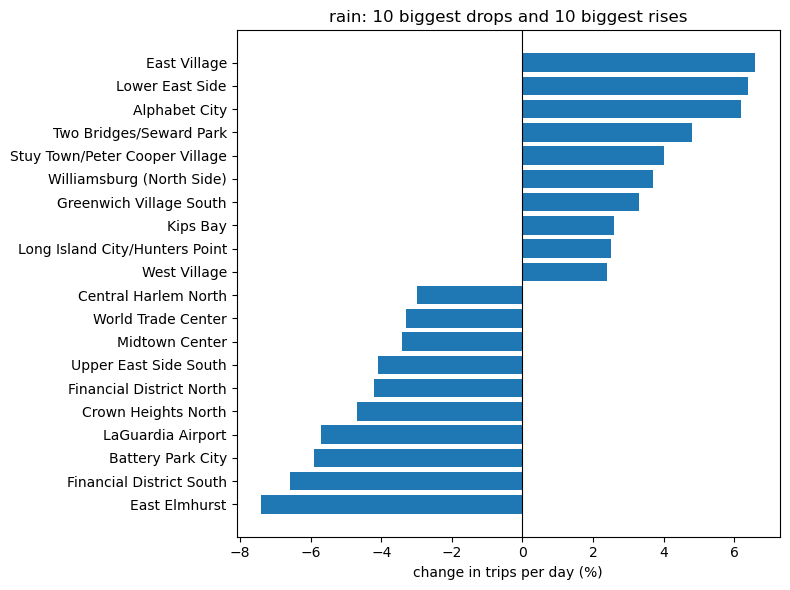

2/12 outputs/charts/rain_duration_pct.png
3/12 outputs/charts/rain_fare_pct.png


In [11]:
draw("rain")

### Step 11: snow

4/12 outputs/charts/snow_trips_pct.png


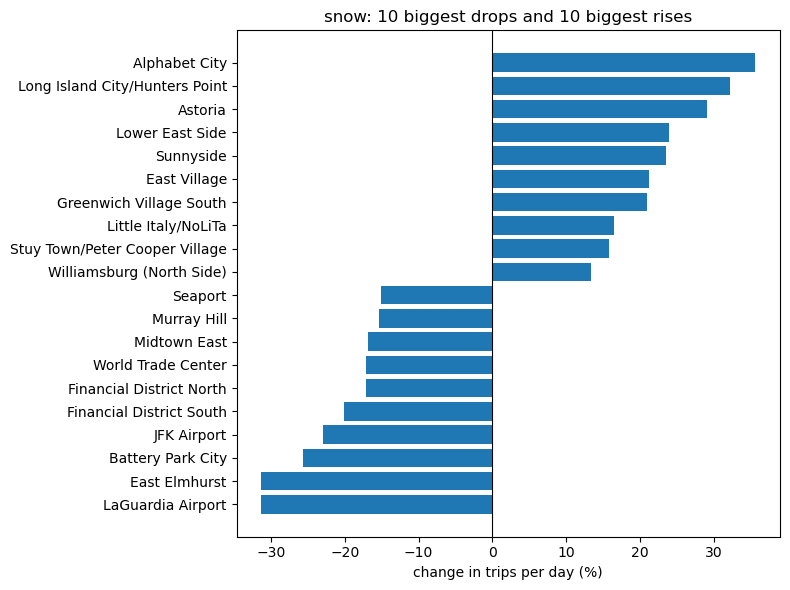

5/12 outputs/charts/snow_duration_pct.png
6/12 outputs/charts/snow_fare_pct.png


In [12]:
draw("snow")

### Step 12: cold

7/12 outputs/charts/cold_trips_pct.png


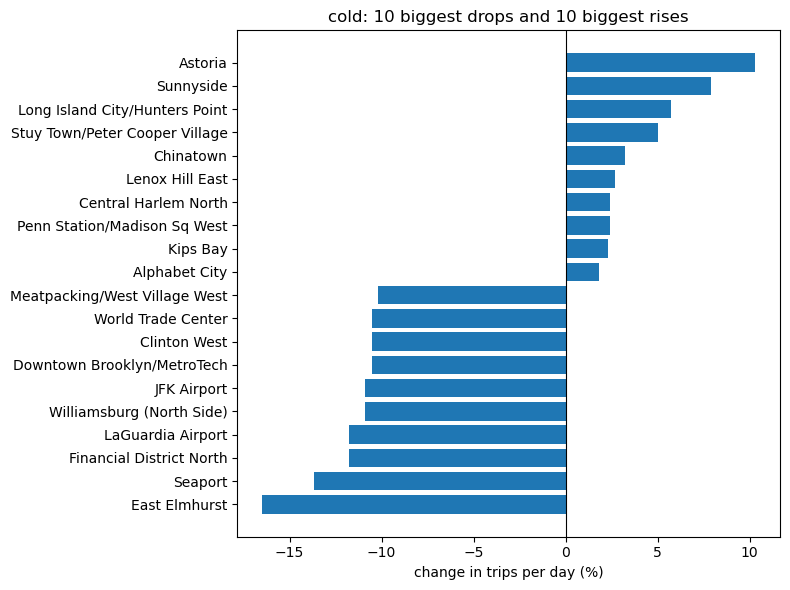

8/12 outputs/charts/cold_duration_pct.png
9/12 outputs/charts/cold_fare_pct.png


In [13]:
draw("cold")

### Step 13: hot

10/12 outputs/charts/hot_trips_pct.png


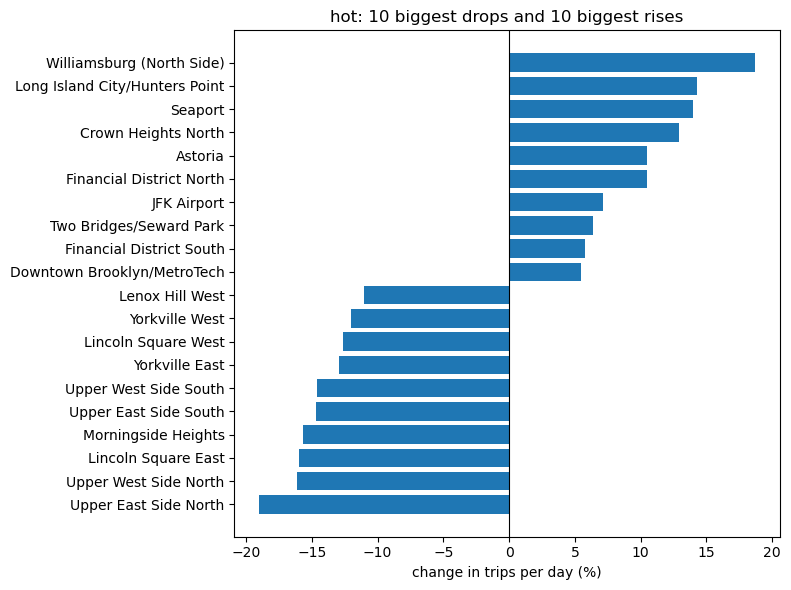

11/12 outputs/charts/hot_duration_pct.png
12/12 outputs/charts/hot_fare_pct.png


In [14]:
draw("hot")

All results are in the `outputs/` folder: `outputs/results/` has one csv per weather type and `outputs/charts/` has the 12 charts.